# Overview (PyTorch Edition)
> **Chuyển đổi từ Keras sang PyTorch** — Thành viên 1: Lý Hồng Hưng (MSSV: 3123411132)
- **MNIST dataset**:
  + Goal: Recognizing handwritten digits
  + Input: a 28x28 grayscale image — **Lưu ý**: Keras dùng `NHWC (28, 28, 1)`, còn PyTorch dùng `NCHW (1, 28, 28)`.
  + Output: class label (0, 1, ..., 9)
- Defining a CNN + MLP (`nn.Module`) for MNIST
- Training and evaluating in PyTorch
- Extracting intermediate features (`fc2` và `pool3 + GlobalAveragePooling2D`) và trực quan hóa không gian đặc trưng bằng **PCA + Seaborn**.

# Import libraries

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

try:
    from torchinfo import summary
except ImportError:
    summary = None
    print("Gợi ý: cài đặt torchinfo bằng lệnh `pip install torchinfo` để hiển thị bảng tóm tắt chi tiết.")

# Cố định seed và chọn thiết bị
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch version:", torch.__version__)
print("Using device   :", device)

Gợi ý: cài đặt torchinfo bằng lệnh `pip install torchinfo` để hiển thị bảng tóm tắt chi tiết.
PyTorch version: 2.14.1+cu130
Using device   : cuda


In [2]:
num_classes = 10   # 10 classes: 0, 1, ..., 9

# (1) Data

In [3]:
# Tải tập dữ liệu MNIST qua torchvision
# transforms.ToTensor() chuyển ảnh về tensor định dạng NCHW (1, 28, 28), float32, chuẩn hóa về [0, 1]
transform = transforms.ToTensor()

train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

print(len(train_dataset), 'train samples')
print(len(test_dataset), 'test samples')

# Minh họa one-hot vector trong PyTorch (tương đương keras.utils.to_categorical(2, num_classes=3))
# Lưu ý: nn.CrossEntropyLoss() trong PyTorch nhận nhãn số nguyên (0..9), không cần chuyển sang one-hot.
print("F.one_hot(2, num_classes=3):", F.one_hot(torch.tensor(2), num_classes=3).float().numpy())

100%|██████████| 9.91M/9.91M [00:00<00:00, 15.1MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 408kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.78MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 16.4MB/s]

60000 train samples
10000 test samples
F.one_hot(2, num_classes=3): [0. 0. 1.]


# (2) Declare model

In [4]:
class MNIST_CNN(nn.Module):
    """Kiến trúc CNN + MLP cho MNIST (chuyển đổi 1:1 từ bản Keras gốc):
    - Block 1: Conv2d(1 -> 64, 3x3, same) + ReLU -> MaxPool2d(2x2) -> Dropout(0.2)   [28x28 -> 14x14]
    - Block 2: Conv2d(64 -> 128, 3x3, same) + ReLU -> MaxPool2d(2x2) -> Dropout(0.2) [14x14 -> 7x7]
    - Block 3: Conv2d(128 -> 256, 3x3, same) + ReLU -> MaxPool2d(2x2) -> Dropout(0.2)[7x7 -> 3x3]
    - Classifier: Flatten(256*3*3 = 2304) -> FC1(512, ReLU) -> Dropout(0.2)
                  -> FC2(512, ReLU) -> Dropout(0.2) -> FC3(10 logits)
    """
    def __init__(self, num_classes=10):
        super().__init__()
        # Các khối tích chập (Feature Extractor)
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=64, kernel_size=3, padding='same')
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.conv_dropout1 = nn.Dropout(p=0.2)

        self.conv2 = nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, padding='same')
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.conv_dropout2 = nn.Dropout(p=0.2)

        self.conv3 = nn.Conv2d(in_channels=128, out_channels=256, kernel_size=3, padding='same')
        self.pool3 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.conv_dropout3 = nn.Dropout(p=0.2)

        # Các lớp Fully Connected (Classifier)
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(256 * 3 * 3, 512)
        self.fc_dropout1 = nn.Dropout(p=0.2)

        self.fc2 = nn.Linear(512, 512)
        self.fc_dropout2 = nn.Dropout(p=0.2)

        self.fc3 = nn.Linear(512, num_classes)

        # Lớp Global Average Pooling (dùng khi trích xuất đặc trưng pool3 ở phần sau)
        self.gap = nn.AdaptiveAvgPool2d((1, 1))

    def forward_features(self, x):
        x = self.conv_dropout1(self.pool1(F.relu(self.conv1(x))))
        x = self.conv_dropout2(self.pool2(F.relu(self.conv2(x))))
        p3 = self.pool3(F.relu(self.conv3(x)))
        x = self.conv_dropout3(p3)
        x = self.flatten(x)
        x = self.fc_dropout1(F.relu(self.fc1(x)))
        fc2_out = F.relu(self.fc2(x))
        x = self.fc_dropout2(fc2_out)
        logits = self.fc3(x)
        return p3, fc2_out, logits

    def forward(self, x):
        _, _, logits = self.forward_features(x)
        return logits


model = MNIST_CNN(num_classes=num_classes).to(device)
print(model)

if summary is not None:
    print(summary(model, input_size=(1, 1, 28, 28), device=device))
else:
    total_params = sum(p.numel() for p in model.parameters())
    print(f"Total params: {total_params:,}")

MNIST_CNN(
  (conv1): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv_dropout1): Dropout(p=0.2, inplace=False)
  (conv2): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv_dropout2): Dropout(p=0.2, inplace=False)
  (conv3): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (pool3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv_dropout3): Dropout(p=0.2, inplace=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=2304, out_features=512, bias=True)
  (fc_dropout1): Dropout(p=0.2, inplace=False)
  (fc2): Linear(in_features=512, out_features=512, bias=True)
  (fc_dropout2): Dropout(p=0.2, inplace=False)
  (fc3): Linear(in_features=512, out_features=10, bias=True)
  (gap): AdaptiveAvgPool2d(outp

# (3) Train defined model
- Lịch sử huấn luyện được lưu vào biến `history`.
- Nếu gặp lỗi thiếu bộ nhớ (OOM), hãy giảm `batch_size`.

In [5]:
# Khai báo siêu tham số, loss function và optimizer (giữ nguyên lr=0.01, SGD, batch_size=128, epochs=30)
batch_size = 128
epochs = 30
lr = 0.01

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=lr)

history = {
    "loss": [],
    "accuracy": [],
    "val_loss": [],
    "val_accuracy": [],
}


def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            total_loss += loss.item() * images.size(0)
            preds = outputs.argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)
    return total_loss / total, correct / total


starting_time = time.time()
for epoch in range(1, epochs + 1):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        preds = outputs.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = correct / total
    val_loss, val_acc = evaluate(model, test_loader, criterion, device)

    history["loss"].append(train_loss)
    history["accuracy"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_acc)

    print(f"Epoch {epoch:02d}/{epochs} - loss: {train_loss:.4f} - accuracy: {train_acc:.4f} - val_loss: {val_loss:.4f} - val_accuracy: {val_acc:.4f}")

print('> training time is %.4f minutes' % ((time.time() - starting_time) / 60))

Epoch 01/30 - loss: 2.2998 - accuracy: 0.1320 - val_loss: 2.2958 - val_accuracy: 0.1317
Epoch 02/30 - loss: 2.2899 - accuracy: 0.2259 - val_loss: 2.2748 - val_accuracy: 0.3297
Epoch 03/30 - loss: 2.1559 - accuracy: 0.3456 - val_loss: 1.5508 - val_accuracy: 0.6001
Epoch 04/30 - loss: 0.9930 - accuracy: 0.6686 - val_loss: 0.5559 - val_accuracy: 0.8377
Epoch 05/30 - loss: 0.5846 - accuracy: 0.8103 - val_loss: 0.3483 - val_accuracy: 0.8924
Epoch 06/30 - loss: 0.3991 - accuracy: 0.8711 - val_loss: 0.2273 - val_accuracy: 0.9302
Epoch 07/30 - loss: 0.3039 - accuracy: 0.9030 - val_loss: 0.1747 - val_accuracy: 0.9455
Epoch 08/30 - loss: 0.2450 - accuracy: 0.9213 - val_loss: 0.1348 - val_accuracy: 0.9583
Epoch 09/30 - loss: 0.2016 - accuracy: 0.9362 - val_loss: 0.1158 - val_accuracy: 0.9623
Epoch 10/30 - loss: 0.1790 - accuracy: 0.9434 - val_loss: 0.0978 - val_accuracy: 0.9696
Epoch 11/30 - loss: 0.1563 - accuracy: 0.9515 - val_loss: 0.0845 - val_accuracy: 0.9725
Epoch 12/30 - loss: 0.1443 - acc

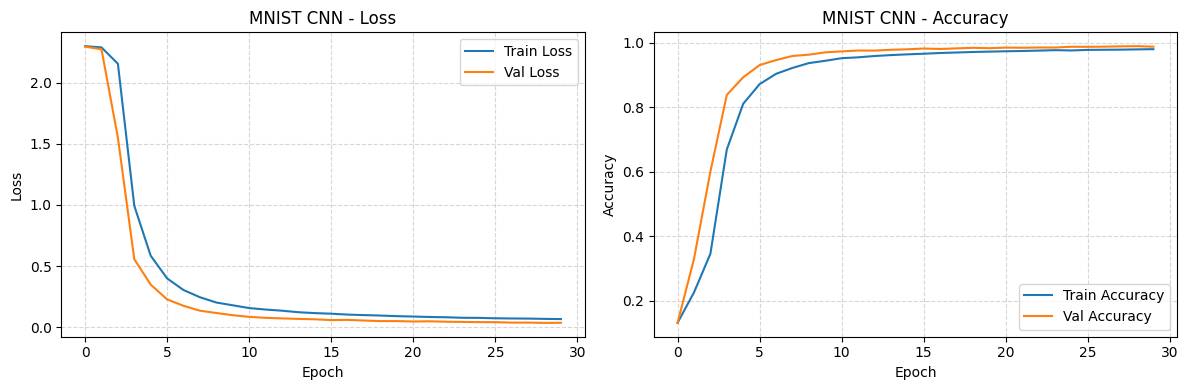

In [6]:
# Vẽ biểu đồ Loss và Accuracy qua các epoch
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history["loss"], label="Train Loss")
axes[0].plot(history["val_loss"], label="Val Loss")
axes[0].set_title("MNIST CNN - Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.5)

axes[1].plot(history["accuracy"], label="Train Accuracy")
axes[1].plot(history["val_accuracy"], label="Val Accuracy")
axes[1].set_title("MNIST CNN - Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

### Tham khảo thời gian huấn luyện bản Keras gốc
- GTX 1080: ~4.2231 phút / 30 epochs (Test accuracy ~98.84% – 98.89%)
- Core i7: ~105.5 phút / 30 epochs

# (4) Evaluate trained model

In [7]:
test_loss, test_acc = evaluate(model, test_loader, criterion, device)
print('Test loss:', test_loss)
print('Test accuracy:', test_acc)

Test loss: 0.03567076066704467
Test accuracy: 0.9871


### (4.1) Trực quan hóa dữ liệu MNIST gốc bằng PCA (2D)

Raw data shape: (60000, 784) | Labels shape: (60000,)
PCA reduced shape: (60000, 2)


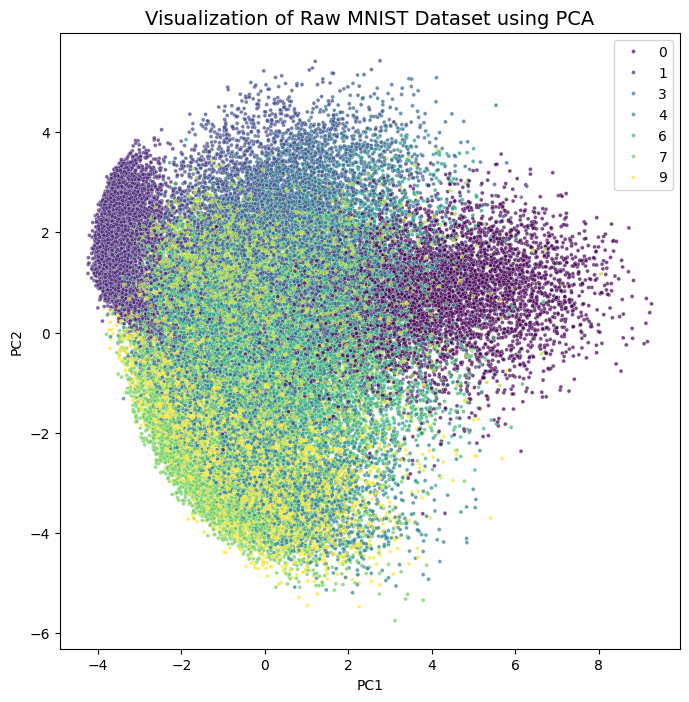

In [8]:
# Lấy toàn bộ ảnh gốc (60000, 784) và nhãn (60000,) để chạy PCA
data_org = (train_dataset.data.numpy().astype(np.float32) / 255.0).reshape(-1, 28 * 28)
data_lbl = train_dataset.targets.numpy()
print("Raw data shape:", data_org.shape, "| Labels shape:", data_lbl.shape)

pca = PCA(n_components=2)
org_pca = pca.fit_transform(data_org)
print("PCA reduced shape:", org_pca.shape)

plt.figure(figsize=(8, 8))
sns.scatterplot(x=org_pca[:, 0], y=org_pca[:, 1], hue=data_lbl, palette='viridis', s=8, alpha=0.7)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Visualization of Raw MNIST Dataset using PCA', fontsize=14)
plt.show()

### (4.2) Liệt kê các lớp trong mô hình & Dự đoán một ảnh ngẫu nhiên

Danh sách các lớp trong MNIST_CNN:
 - conv1
 - pool1
 - conv_dropout1
 - conv2
 - pool2
 - conv_dropout2
 - conv3
 - pool3
 - conv_dropout3
 - flatten
 - fc1
 - fc_dropout1
 - fc2
 - fc_dropout2
 - fc3
 - gap


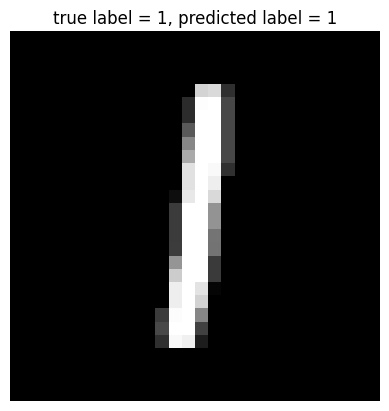

In [9]:
# Liệt kê tên tất cả các module/layer trong mô hình PyTorch
print("Danh sách các lớp trong MNIST_CNN:")
for name, _ in model.named_children():
    print(" -", name)

# Chọn ngẫu nhiên một ảnh kiểm tra và dự đoán
random_test_index = np.random.choice(len(test_dataset), size=1)[0]
test_img_tensor, test_label = test_dataset[random_test_index]

model.eval()
with torch.no_grad():
    logits = model(test_img_tensor.unsqueeze(0).to(device))
    pred_label = logits.argmax(dim=1).item()

plt.imshow(test_img_tensor.squeeze(0).numpy(), cmap='gray')
plt.title(f'true label = {test_label}, predicted label = {pred_label}')
plt.axis('off')
plt.show()

### (4.3) Trích xuất đặc trưng lớp `fc2` (512 chiều) và trực quan hóa bằng PCA

In [10]:
# Dùng DataLoader (shuffle=False) để trích xuất đặc trưng trên 60,000 ảnh mà không gây tràn bộ nhớ
train_eval_loader = DataLoader(train_dataset, batch_size=256, shuffle=False)

fc2_feats_list = []
pool3_gap_feats_list = []
labels_list = []

model.eval()
with torch.no_grad():
    for images, labels in train_eval_loader:
        images = images.to(device)
        p3, fc2_out, _ = model.forward_features(images)

        # Global Average Pooling trên đầu ra pool3: (B, 256, 3, 3) -> (B, 256, 1, 1) -> (B, 256)
        # Tương đương GlobalAveragePooling2D()(model.get_layer("pool3").output) trong Keras
        p3_gap = model.gap(p3).flatten(start_dim=1)

        fc2_feats_list.append(fc2_out.cpu().numpy())
        pool3_gap_feats_list.append(p3_gap.cpu().numpy())
        labels_list.append(labels.numpy())

y_feat = np.concatenate(fc2_feats_list, axis=0)
y2_feat = np.concatenate(pool3_gap_feats_list, axis=0)
all_labels = np.concatenate(labels_list, axis=0)

print("fc2 features shape             :", y_feat.shape)   # (60000, 512)
print("pool3 + GlobalAvgPool shape    :", y2_feat.shape)  # (60000, 256)

fc2 features shape             : (60000, 512)
pool3 + GlobalAvgPool shape    : (60000, 256)


fc2_pca shape: (60000, 2)


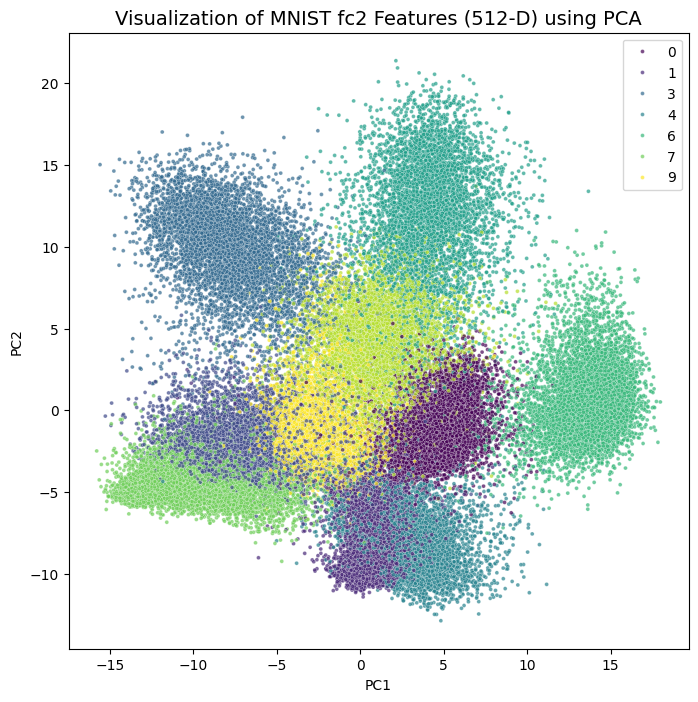

In [11]:
# Giảm chiều đặc trưng fc2 (512 -> 2) bằng PCA và vẽ biểu đồ phân cụm
pca_fc2 = PCA(n_components=2)
fc2_pca = pca_fc2.fit_transform(y_feat)
print("fc2_pca shape:", fc2_pca.shape)

plt.figure(figsize=(8, 8))
sns.scatterplot(x=fc2_pca[:, 0], y=fc2_pca[:, 1], hue=all_labels, palette='viridis', s=8, alpha=0.7)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Visualization of MNIST fc2 Features (512-D) using PCA', fontsize=14)
plt.show()

### (4.4) Trích xuất đặc trưng lớp `pool3` + `GlobalAveragePooling2D` (`nn.AdaptiveAvgPool2d(1)`) và trực quan hóa bằng PCA

y2_pca shape: (60000, 2)


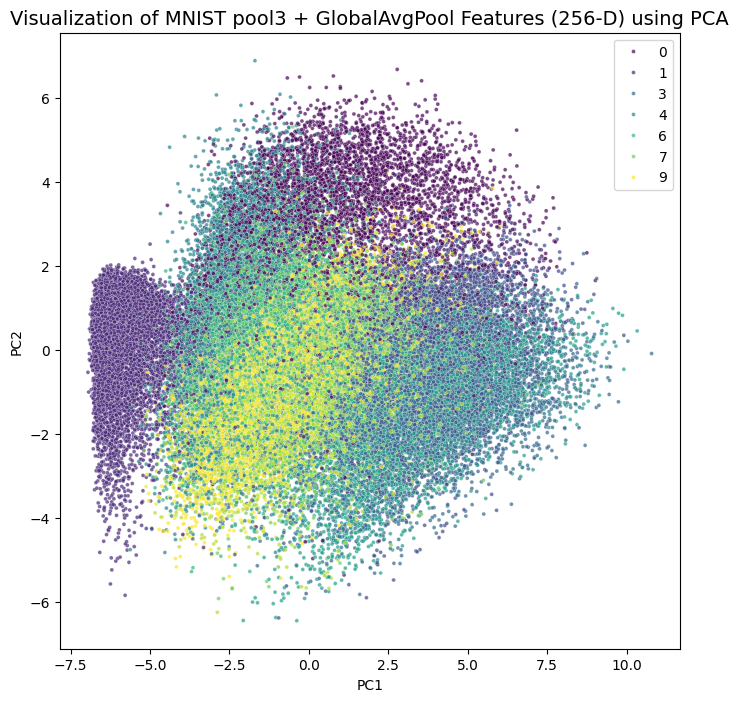

In [12]:
# Giảm chiều đặc trưng pool3 + GAP (256 -> 2) bằng PCA và vẽ biểu đồ phân cụm
pca_y2 = PCA(n_components=2)
y2_pca = pca_y2.fit_transform(y2_feat)
print("y2_pca shape:", y2_pca.shape)

plt.figure(figsize=(8, 8))
sns.scatterplot(x=y2_pca[:, 0], y=y2_pca[:, 1], hue=all_labels, palette='viridis', s=8, alpha=0.7)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Visualization of MNIST pool3 + GlobalAvgPool Features (256-D) using PCA', fontsize=14)
plt.show()